In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [11]:
df = pd.read_csv('Student Social Media And Mental Health Impact.csv')

In [12]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [13]:
df.shape

(5000, 13)

In [14]:
df.isnull().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   str    
 2   Country                  5000 non-null   str    
 3   Academic_Level           5000 non-null   str    
 4   Most_Used_Platform       5000 non-null   str    
 5   Purpose_Of_Use           5000 non-null   str    
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   str    
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), str(6)
memory usage: 736.5 KB


C:\Users\lenovo\AppData\Local\Temp\ipykernel_28668\3673292043.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Mental_Health_Score'],kde = True)


<Axes: xlabel='Mental_Health_Score', ylabel='Density'>

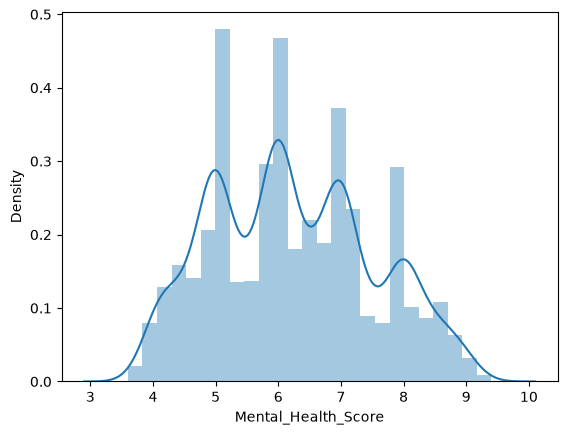

In [16]:
sns.distplot(df['Mental_Health_Score'],kde = True)

<Axes: >

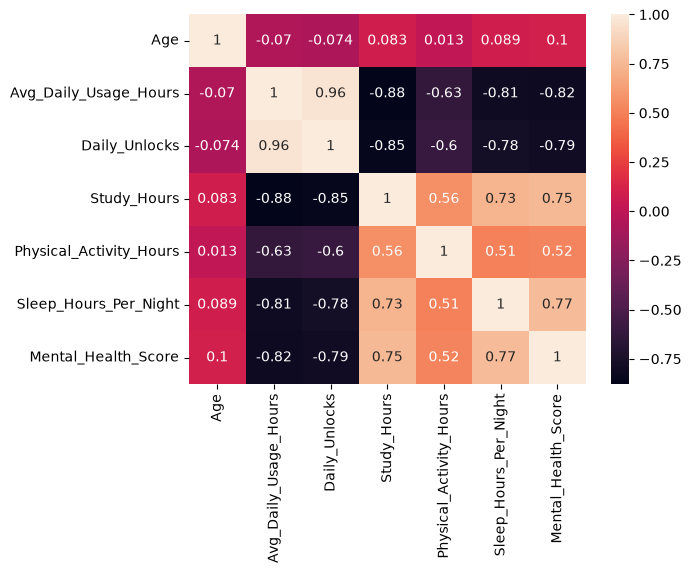

In [17]:
sns.heatmap(df.corr(numeric_only = True), annot = True)

<Axes: xlabel='Physical_Activity_Hours', ylabel='Mental_Health_Score'>

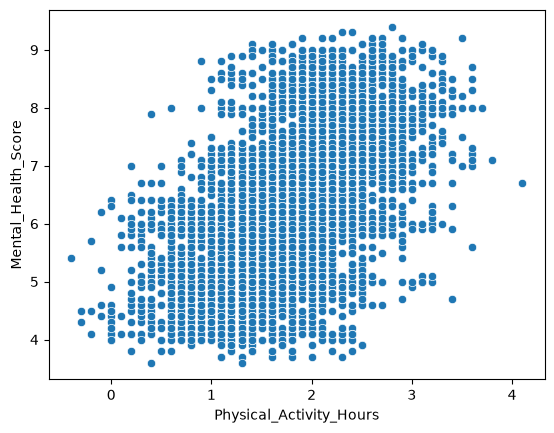

In [18]:
sns.scatterplot( x = 'Physical_Activity_Hours', y = 'Mental_Health_Score', data=df)

Most_Used_Platform
Instagram    1130
TikTok        918
Facebook      719
LinkedIn      523
YouTube       491
Twitter       462
Snapchat      420
WhatsApp      175
LINE           50
VKontakte      40
KakaoTalk      36
WeChat         36
Name: count, dtype: int64

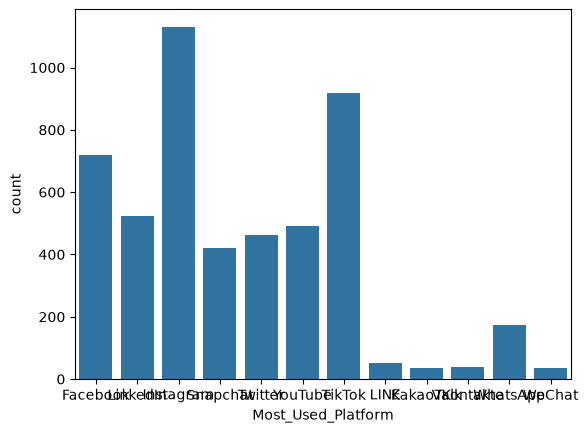

In [19]:

sns.countplot(x = 'Most_Used_Platform', data = df)
Plateform = df['Most_Used_Platform'].value_counts()
Plateform

In [20]:
num_f = df.select_dtypes(include = 'number')
num_f

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
0,21,4.0,134,4.5,2.2,6.7,6.8
1,23,1.6,73,7.0,2.4,8.6,7.6
2,22,4.6,166,4.0,1.8,6.7,7.0
3,18,7.0,220,1.0,1.7,5.4,5.3
4,24,7.5,237,1.0,1.1,5.0,4.4
...,...,...,...,...,...,...,...
4995,18,1.9,89,6.1,2.2,7.9,7.9
4996,18,6.6,216,2.3,1.8,6.0,4.7
4997,19,3.8,151,5.4,1.4,7.5,7.0
4998,18,3.8,119,4.0,1.5,6.4,6.7


In [21]:
    Q1 = num_f.quantile(0.25)
    Q3 = num_f.quantile(0.75)

In [22]:
IQR = Q3 - Q1

In [23]:
lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

In [24]:
outliers = (num_f< lower_bound)| (num_f> upper_bound)
print(outliers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


In [25]:
df = df.drop_duplicates()

In [26]:
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower = 0)  #converting neg unrealistic vale to realistic

In [27]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [28]:
num_cols = df.select_dtypes( include = 'number')

In [29]:
num_cols.skew()

Age                        0.155008
Avg_Daily_Usage_Hours      0.005575
Daily_Unlocks              0.002309
Study_Hours                0.436125
Physical_Activity_Hours    0.053288
Sleep_Hours_Per_Night      0.123919
Mental_Health_Score        0.207086
dtype: float64

In [30]:
#value near to 0 = centralized
#value pos = right skewed
#value neg = left skewed
#log transformation

In [31]:
top = df['Country'].value_counts().index[:10].tolist()


In [32]:
def group_countries(Country):
    if Country in top:
        return Country
    else:
       return 'other'

In [33]:
df['Grouped'] = df['Country'].apply(group_countries)

In [34]:
df['Grouped'].value_counts()

Grouped
Other        1879
other        1352
India         389
USA           354
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Name: count, dtype: int64

In [35]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score', 'Grouped'],
      dtype='str')

In [36]:
df.sample(10)

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Grouped
4887,22,Female,Denmark,Undergraduate,Twitter,News,4.5,162,3.8,1.9,7.4,High,6.8,other
2117,18,Male,Other,High School,Snapchat,Entertainment,6.9,220,1.3,1.2,5.1,Very High,5.2,Other
1446,20,Female,USA,Undergraduate,TikTok,Entertainment,8.0,255,1.0,0.5,4.3,Very High,5.0,USA
968,23,Female,UK,Graduate,Snapchat,Entertainment,7.0,217,1.2,1.5,5.6,High,5.9,UK
4130,24,Male,USA,Graduate,Facebook,Networking,5.1,155,3.8,1.8,7.2,High,6.3,USA
948,19,Female,Other,Undergraduate,LinkedIn,Education,6.0,196,3.2,1.3,6.0,Very High,5.8,Other
2846,20,Female,Switzerland,Undergraduate,Instagram,Entertainment,2.5,93,6.2,2.6,9.9,Low,8.1,other
4240,20,Female,Switzerland,Undergraduate,Instagram,Entertainment,2.9,111,4.6,1.5,8.8,Medium,7.7,other
2750,19,Female,USA,Undergraduate,TikTok,Entertainment,6.8,215,1.6,0.7,5.5,Very High,4.2,USA
2753,20,Female,France,Undergraduate,Instagram,Entertainment,2.8,104,5.2,2.7,9.0,Low,7.3,France


In [37]:
from sklearn.model_selection import train_test_split

In [40]:
x_train,x_test,y_train,y_test = train_test_split(x,y, test_size = 0.30, random_state = 42)

In [41]:
skewed_col = ['Study_Hours'] #log transform
ordinal_col = ['Stress_Level'] # ordinal cause they are in a order
other_col = ['Avg_Daily_Usage_Hours','Age',	'Daily_Unlocks',	'Physical_Activity_Hours',	'Sleep_Hours_Per_Night']#standard scaler in nmerical col
normal_col = ['Gender','Country',	'Academic_Level',	'Most_Used_Platform',	'Purpose_Of_Use', 'Grouped']
feature_col = skewed_col + ordinal_col + other_col + normal_col
x = df[feature_col]
y = df['Mental_Health_Score']
x_train,x_test,y_train,y_test = train_test_split(x,y, test_size = 0.30, random_state = 42)

In [42]:
x_test.shape

(1500, 13)

In [43]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder,OneHotEncoder

skew_pipeline = Pipeline( steps = [
    ('Log Transformation',FunctionTransformer(np.log1p)),
    ('Scaler', StandardScaler())
]
                          
    
)


plain_numeric_pipeline = Pipeline(
    steps = [
        ('Scaler',StandardScaler())
    ]
)


ordinal_pipeline = Pipeline(
    steps = [
        ('ordinal', OrdinalEncoder(categories = [['Low','Medium','High','Very High']]))
    ]
)


nominal_pipeline  = Pipeline(
    steps = [
        ('ohe', OneHotEncoder(handle_unknown = 'ignore'))
    ]
)

In [44]:
from sklearn.compose import ColumnTransformer

In [45]:
preprocessor = ColumnTransformer(transformers = [
    ( 'skew_pipeline', skew_pipeline,skewed_col),
    ('standardscalerpipeline', plain_numeric_pipeline, other_col),
    ('ordinalpipeline',ordinal_pipeline, ordinal_col ),
    ('nominal_pipeline',nominal_pipeline,normal_col)
    
]
                 )  

In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [47]:
lr_pipeline = Pipeline(
    steps = [
        ( 'preprocessor', preprocessor),
        ('linearregression', LinearRegression())
    ]
)
lr_pipeline.fit(x_train,y_train)
lr_pred_test = lr_pipeline.predict(x_test)
lr_pred_train = lr_pipeline.predict(x_train)
lr_r2_test = r2_score(y_test,lr_pred_test)
lr_r2_train = r2_score(y_train, lr_pred_train)

In [48]:
lr_r2_test

0.7866975274954889

In [49]:
lr_r2_train

0.7800764393928369

In [50]:
#no overfitting
from sklearn.ensemble import RandomForestRegressor

In [51]:
rf_pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('random forest',RandomForestRegressor(random_state = 42))
    ]
)

In [52]:
rf_pipeline.fit(x_train,y_train)
rf_pred_test = rf_pipeline.predict(x_test)


In [53]:
rf_pred_train = rf_pipeline.predict(x_train)

In [54]:
rf_r2_score_testing = r2_score(y_test,rf_pred_test)

In [55]:
rf_r2_score_testing

0.9122522511461983

In [56]:
rf_r2_training = r2_score(y_train, rf_pred_train)

In [ ]:
rf_r2_training  #little bit of overfitting


In [58]:
#hyperparameter tuning to reduce accuracy gap bw training and testing

In [59]:
from sklearn.model_selection import RandomizedSearchCV

In [60]:
param_grid = {
    'random forest__n_estimators': [100,200,300],
    'random forest__max_depth' : [5,10,15],
    'random forest__min_samples_split' : [2,5,10],
    'random forest__min_samples_leaf' : [1,2,4]
}

In [61]:
random_search = RandomizedSearchCV(
    estimator = rf_pipeline,
    param_distributions = param_grid,
    n_iter = 15,
    cv = 5,
    scoring = 'r2',
    random_state = 42,
    n_jobs = -1
)

In [62]:
random_search.fit(x_train,y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'random forest__max_depth': [5, 10, ...], 'random forest__min_samples_leaf': [1, 2, ...], 'random forest__min_samples_split': [2, 5, ...], 'random forest__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` dire

In [66]:
random_search.best_params_

{'random forest__n_estimators': 200,
 'random forest__min_samples_split': 5,
 'random forest__min_samples_leaf': 2,
 'random forest__max_depth': 15}

In [69]:
rf_best_pipeline = random_search.best_estimator_
rf_pred_best = rf_best_pipeline.predict(x_test)
print('R2 score of random forest after hyperparametertuning:', r2_score(y_test,rf_pred_best))
mean_absolute_error(y_test,rf_pred_best)

R2 score of random forest after hyperparametertuning: 0.8942421920396071


0.31686671203574635

In [71]:
#we will choose random forest without hyperparameter tuning cause it has the highest test results

In [72]:
import joblib

In [73]:
joblib.dump(rf_pipeline, 'Mental_Health_Model.pkl')

['Mental_Health_Model.pkl']